In [18]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn joblib

import os
import re
import random
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ============================================================
# COMPLETE DATA AUGMENTATION BLOCK
# AI PUBLIC HEALTH CHATBOT
# ============================================================
#
# Upload:
#     Symptom2Disease.csv  <-- ORIGINAL 1200-row dataset
#
# Creates:
#     Symptom2Disease_augmented.csv
#
# Original examples : 1200
# New examples      : 192
# Expected total    : 1392
# ============================================================

import pandas as pd
from google.colab import files

# ============================================================
# 1. UPLOAD ORIGINAL DATASET
# ============================================================

print("Please upload the ORIGINAL Symptom2Disease.csv file.")
uploaded = files.upload()

# Check uploaded filename
uploaded_filename = list(uploaded.keys())[0]

print("\nUploaded file:", uploaded_filename)

# Read dataset
df = pd.read_csv(uploaded_filename)

print("\nOriginal dataset shape:", df.shape)
print("Original columns:", df.columns.tolist())

# Make sure required columns exist
if "label" not in df.columns or "text" not in df.columns:
    raise ValueError(
        "Dataset must contain 'label' and 'text' columns."
    )

print("\nFirst 5 rows:")
display(df.head())


# ============================================================
# 2. PARAPHRASED TRAINING EXAMPLES
# ============================================================

augmentation_data = {

    "Acne": [
        "I have pimples and blackheads on my face.",
        "My skin has many small pimples and whiteheads.",
        "I am getting frequent breakouts on my face.",
        "I have red bumps and pimples on my skin.",
        "My face has acne and clogged pores.",
        "I have several inflamed spots and pimples.",
        "I keep developing pimples around my face and forehead.",
        "My skin is breaking out with pimples and blackheads."
    ],

    "Arthritis": [
        "I have pain and stiffness in my joints.",
        "My joints are swollen and painful.",
        "I experience joint pain that makes movement difficult.",
        "My knees and other joints feel stiff and sore.",
        "I have aching joints, especially when I move.",
        "My joints hurt and feel stiff after resting.",
        "I experience swelling and discomfort around my joints.",
        "My joints feel painful, stiff, and difficult to move."
    ],

    "Bronchial Asthma": [
        "I have difficulty breathing and sometimes wheeze.",
        "I feel tightness in my chest and have trouble breathing.",
        "I experience wheezing and shortness of breath.",
        "My breathing becomes difficult and I hear a wheezing sound.",
        "I sometimes feel like I cannot get enough air.",
        "I have repeated episodes of breathlessness and chest tightness.",
        "I start wheezing when I have difficulty breathing.",
        "I experience shortness of breath along with chest tightness."
    ],

    "Cervical spondylosis": [
        "I have persistent neck pain and stiffness.",
        "My neck feels stiff and painful when I move it.",
        "I have neck pain that sometimes spreads toward my shoulders.",
        "I experience stiffness in my neck and discomfort around my shoulders.",
        "My neck hurts and I have difficulty moving it freely.",
        "I have pain and stiffness around my neck.",
        "I experience neck discomfort along with shoulder pain.",
        "My neck feels stiff, sore, and painful during movement."
    ],

    "Chicken pox": [
        "I have an itchy rash with small fluid-filled blisters.",
        "I have red spots and itchy blisters on my skin.",
        "I developed an itchy blister-like rash along with fever.",
        "My skin has many small itchy blisters.",
        "I have a spreading rash with fluid-filled spots.",
        "I developed red itchy spots that turned into blisters.",
        "I have fever followed by an itchy blistering rash.",
        "My body has itchy red spots and small blisters."
    ],

    "Common Cold": [
        "I have a runny nose and keep sneezing.",
        "I have a blocked nose, sore throat, and mild cough.",
        "I am sneezing frequently and have a runny nose.",
        "My throat is sore and I have nasal congestion.",
        "I have a cough, runny nose, and sneezing.",
        "I feel congested and have irritation in my throat.",
        "I have cold-like symptoms with sneezing and a stuffy nose.",
        "My nose is blocked and running, and I have a sore throat."
    ],

    "Dengue": [
        "I have a high fever with severe headache and body pain.",
        "I have fever, muscle pain, and pain behind my eyes.",
        "I feel extremely weak with fever and severe body aches.",
        "I have a high fever and intense muscle and joint pain.",
        "I have fever along with headache and pain behind my eyes.",
        "I feel very tired and have severe aches with a high fever.",
        "I have fever, weakness, headache, and strong muscle pain.",
        "I have a high fever with body aches and pain around my eyes."
    ],

    "Dimorphic Hemorrhoids": [
        "I have bleeding and discomfort during bowel movements.",
        "I notice blood when I pass stool and have anal discomfort.",
        "I have itching and pain around the anus.",
        "I experience bleeding during bowel movements.",
        "I have discomfort and itching around my rectal area.",
        "I notice bleeding along with pain when passing stool.",
        "I have swelling and irritation around the anus.",
        "I experience rectal discomfort, itching, and bleeding."
    ],

    "Fungal infection": [
        "I have an itchy red rash on my skin.",
        "My skin is irritated, itchy, and flaky.",
        "I have red patches with itching and scaling.",
        "I developed a persistent itchy skin rash.",
        "My skin has irritated patches that are becoming scaly.",
        "I have redness, itching, and peeling of the skin.",
        "There are itchy and flaky patches on my skin.",
        "I have a red, irritated rash that keeps itching."
    ],

    "Hypertension": [
        "I have been told that my blood pressure is high.",
        "My blood pressure readings are consistently elevated.",
        "I have high blood pressure and sometimes get headaches.",
        "My blood pressure has been higher than normal.",
        "I have been experiencing headaches along with high blood pressure.",
        "My blood pressure remains elevated when I check it.",
        "I was told that I have hypertension.",
        "I have high blood pressure and occasionally feel dizzy."
    ],

    "Impetigo": [
        "I have red sores on my skin that develop yellow crusts.",
        "I noticed small skin sores covered with a golden crust.",
        "My skin has red lesions with yellowish crusting.",
        "I have itchy sores that are forming crusts.",
        "I developed small red sores that started crusting.",
        "There are crusted sores around my skin.",
        "I have skin lesions with a yellow-brown crust.",
        "My skin has small sores that ooze and form crusts."
    ],

    "Jaundice": [
        "My skin has become yellowish and I feel very tired.",
        "My eyes look yellow and I feel weak.",
        "I noticed yellowing of my skin and eyes.",
        "My skin is turning yellow and I have been feeling fatigued.",
        "I have yellowish skin and dark-colored urine.",
        "My eyes have a yellow tint and I feel unusually tired.",
        "I have noticed a yellow discoloration of my skin.",
        "My skin and eyes look yellow and I feel exhausted."
    ],

    "Malaria": [
        "I have recurring fever with chills and sweating.",
        "I experience fever followed by chills and weakness.",
        "I have episodes of high fever and severe chills.",
        "I feel very weak and have repeated fever and chills.",
        "I have fever, sweating, headache, and body weakness.",
        "My fever comes with chills and intense tiredness.",
        "I experience recurring fever with headache and chills.",
        "I have episodes of fever followed by sweating and weakness."
    ],

    "Migraine": [
        "I have a severe headache with nausea.",
        "Bright light makes my headache worse.",
        "I experience intense headaches and sensitivity to light.",
        "My headache is accompanied by nausea.",
        "I get severe headaches and feel sick.",
        "I have a throbbing headache with nausea.",
        "I experience strong headaches and sensitivity to sound.",
        "I get intense headaches that become worse with bright light."
    ],

    "Pneumonia": [
        "I have a cough, fever, and difficulty breathing.",
        "I have chest pain along with a persistent cough.",
        "I am experiencing fever, cough, and shortness of breath.",
        "I have difficulty breathing and pain in my chest.",
        "My cough is accompanied by fever and weakness.",
        "I have a persistent cough with breathing difficulties.",
        "I feel short of breath and have a fever with coughing.",
        "I have chest discomfort, fever, and a severe cough."
    ],

    "Psoriasis": [
        "I have dry, thick, scaly patches on my skin.",
        "My skin has red patches covered with scales.",
        "I have itchy and flaky patches of skin.",
        "I developed thick, dry areas on my skin that keep peeling.",
        "My skin has raised red patches with silvery scales.",
        "I have persistent scaly patches that are itchy.",
        "There are dry, thick patches appearing on my skin.",
        "I have red irritated areas covered with flaky scales."
    ],

    "Typhoid": [
        "I have a persistent fever and feel very weak.",
        "I have prolonged fever with stomach discomfort.",
        "I feel tired and have a fever that does not go away.",
        "I have fever, weakness, and loss of appetite.",
        "I have a persistent high temperature with abdominal discomfort.",
        "I feel weak and have been experiencing fever for several days.",
        "I have fever along with stomach problems and tiredness.",
        "I have prolonged fever, weakness, and reduced appetite."
    ],

    "Varicose Veins": [
        "I have swollen and twisted veins in my legs.",
        "The veins in my legs look enlarged and prominent.",
        "I have visible bulging veins on my legs.",
        "My legs feel heavy and the veins look swollen.",
        "I have enlarged veins that are visible beneath my skin.",
        "My legs ache and I can see twisted veins.",
        "I have prominent veins in my legs with aching and heaviness.",
        "The veins in my legs appear swollen and twisted."
    ],

    "allergy": [
        "I have itching, sneezing, and a runny nose.",
        "I keep sneezing and my eyes are itchy.",
        "I developed an itchy rash after exposure to something.",
        "I have watery eyes and frequent sneezing.",
        "My nose is running and I keep feeling itchy.",
        "I experience sneezing, itching, and irritation.",
        "My eyes are watery and itchy and I keep sneezing.",
        "I developed itching and a rash after coming into contact with something."
    ],

    "diabetes": [
        "I am extremely thirsty and urinate frequently.",
        "I feel thirsty all the time and need to urinate often.",
        "I have increased hunger and frequent urination.",
        "I feel unusually thirsty and hungry.",
        "I have been drinking much more water than usual.",
        "I frequently need to use the bathroom and feel very thirsty.",
        "I have excessive thirst, increased hunger, and frequent urination.",
        "I am constantly thirsty and have been urinating more than usual."
    ],

    "drug reaction": [
        "I developed a rash after taking a medicine.",
        "My skin became itchy after I started a new medication.",
        "I have itching and a rash after taking a drug.",
        "I noticed skin irritation after using a new medicine.",
        "I developed red spots and itching after taking medication.",
        "My skin reacted after I took a new medicine.",
        "I have an unusual rash that appeared after taking medicine.",
        "I started experiencing itching and skin changes after medication."
    ],

    "gastroesophageal reflux disease": [
        "I frequently experience heartburn.",
        "I feel acid coming back into my throat.",
        "I get a burning sensation after eating.",
        "I have acid reflux after meals.",
        "I experience burning in my chest after eating.",
        "I often feel a sour taste coming back into my mouth.",
        "I have a burning feeling in my chest and throat after meals.",
        "I frequently experience acid reflux and heartburn."
    ],

    "peptic ulcer disease": [
        "I have a burning pain in my stomach.",
        "I experience stomach pain when my stomach is empty.",
        "I have recurring pain and burning in my upper abdomen.",
        "I feel a burning sensation in my stomach between meals.",
        "I have upper abdominal discomfort and pain.",
        "I experience stomach pain that sometimes improves after eating.",
        "I have a recurring burning sensation in my abdomen.",
        "I feel pain and discomfort in my upper stomach."
    ],

    "urinary tract infection": [
        "It burns when I urinate.",
        "I need to urinate very frequently.",
        "I feel pain while passing urine.",
        "I have a constant urge to urinate.",
        "I experience burning and discomfort when urinating.",
        "I feel like I need to urinate even when very little comes out.",
        "I have frequent urination along with a burning sensation.",
        "I experience pain and irritation when I pass urine."
    ]
}


# ============================================================
# 3. VERIFY ALL 24 LABELS
# ============================================================

original_labels = set(df["label"].unique())
augmentation_labels = set(augmentation_data.keys())

missing_labels = original_labels - augmentation_labels
extra_labels = augmentation_labels - original_labels

print("\nNumber of original classes:", len(original_labels))
print("Number of augmentation classes:", len(augmentation_labels))

if missing_labels:
    print("\nWARNING: Missing labels:")
    print(missing_labels)
    raise ValueError("Some original dataset labels do not have augmentation data.")

if extra_labels:
    print("\nWARNING: Extra labels:")
    print(extra_labels)
    raise ValueError("Some augmentation labels do not exist in the dataset.")

print("\n✓ All 24 dataset classes are covered.")


# ============================================================
# 4. CREATE AUGMENTED ROWS
# ============================================================

new_rows = []

for label, sentences in augmentation_data.items():

    for sentence in sentences:

        new_rows.append({
            "label": label,
            "text": sentence
        })

augmentation_df = pd.DataFrame(new_rows)

print("\nNew paraphrased examples:", len(augmentation_df))


# ============================================================
# 5. COMBINE ORIGINAL + NEW DATA
# ============================================================

original_training_data = df[["label", "text"]].copy()

augmented_df = pd.concat(
    [
        original_training_data,
        augmentation_df
    ],
    ignore_index=True
)


# ============================================================
# 6. REMOVE EXACT DUPLICATES
# ============================================================

before = len(augmented_df)

augmented_df = augmented_df.drop_duplicates(
    subset=["label", "text"]
).reset_index(drop=True)

after = len(augmented_df)

print("Duplicate rows removed:", before - after)


# ============================================================
# 7. SHUFFLE DATASET
# ============================================================

augmented_df = augmented_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ============================================================
# 8. ADD INDEX COLUMN
# ============================================================

augmented_df.insert(
    0,
    "Unnamed: 0",
    range(len(augmented_df))
)


# ============================================================
# 9. SAVE AUGMENTED DATASET
# ============================================================

output_file = "Symptom2Disease_augmented.csv"

augmented_df.to_csv(
    output_file,
    index=False
)


# ============================================================
# 10. RESULTS
# ============================================================

print("\n" + "=" * 60)
print("DATA AUGMENTATION COMPLETE")
print("=" * 60)

print("\nOriginal examples :", len(df))
print("New examples      :", len(augmentation_df))
print("Final examples    :", len(augmented_df))

print("\nOutput file:")
print(output_file)

print("\nFinal shape:")
print(augmented_df.shape)

print("\nFinal columns:")
print(augmented_df.columns.tolist())


# ============================================================
# 11. CLASS DISTRIBUTION
# ============================================================

print("\nClass distribution:")

print(
    augmented_df["label"].value_counts()
)


# ============================================================
# 12. SHOW SAMPLE NEW EXAMPLES
# ============================================================

print("\nSample newly added examples:")

display(
    augmentation_df.head(15)
)


# ============================================================
# 13. DOWNLOAD AUGMENTED DATASET
# ============================================================

print("\nDownloading augmented dataset...")

files.download(output_file)

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Please upload the ORIGINAL Symptom2Disease.csv file.


Saving Symptom2Disease.csv to Symptom2Disease (3).csv

Uploaded file: Symptom2Disease (3).csv

Original dataset shape: (1200, 3)
Original columns: ['Unnamed: 0', 'label', 'text']

First 5 rows:


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."



Number of original classes: 24
Number of augmentation classes: 24

✓ All 24 dataset classes are covered.

New paraphrased examples: 192
Duplicate rows removed: 47

DATA AUGMENTATION COMPLETE

Original examples : 1200
New examples      : 192
Final examples    : 1345

Output file:
Symptom2Disease_augmented.csv

Final shape:
(1345, 3)

Final columns:
['Unnamed: 0', 'label', 'text']

Class distribution:
label
Dengue                             58
Fungal infection                   58
Impetigo                           58
Varicose Veins                     58
Typhoid                            58
Psoriasis                          58
Hypertension                       58
allergy                            58
drug reaction                      58
urinary tract infection            58
peptic ulcer disease               58
diabetes                           58
Cervical spondylosis               57
Common Cold                        57
Chicken pox                        57
Bronchial Asthma    

,label,text
0,Acne,I have pimples and blackheads on my face.
1,Acne,My skin has many small pimples and whiteheads.
2,Acne,I am getting frequent breakouts on my face.
3,Acne,I have red bumps and pimples on my skin.
4,Acne,My face has acne and clogged pores.
5,Acne,I have several inflamed spots and pimples.
6,Acne,I keep developing pimples around my face and f...
7,Acne,My skin is breaking out with pimples and black...
8,Arthritis,I have pain and stiffness in my joints.
9,Arthritis,My joints are swollen and painful.


Shape: (1345, 3)

Columns:
['Unnamed: 0', 'label', 'text']

Data types:
Unnamed: 0     int64
label         object
text          object
dtype: object

Missing values:
Unnamed: 0    0
label         0
text          0
dtype: int64

Duplicates: 0
['text', 'label']
Final shape: (1345, 2)
Number of disease classes: 24

Disease classes:
- Acne
- Arthritis
- Bronchial Asthma
- Cervical spondylosis
- Chicken pox
- Common Cold
- Dengue
- Dimorphic Hemorrhoids
- Fungal infection
- Hypertension
- Impetigo
- Jaundice
- Malaria
- Migraine
- Pneumonia
- Psoriasis
- Typhoid
- Varicose Veins
- allergy
- diabetes
- drug reaction
- gastroesophageal reflux disease
- peptic ulcer disease
- urinary tract infection
label
Dengue                             58
Fungal infection                   58
Impetigo                           58
Varicose Veins                     58
Typhoid                            58
Psoriasis                          58
Hypertension                       58
allergy                    

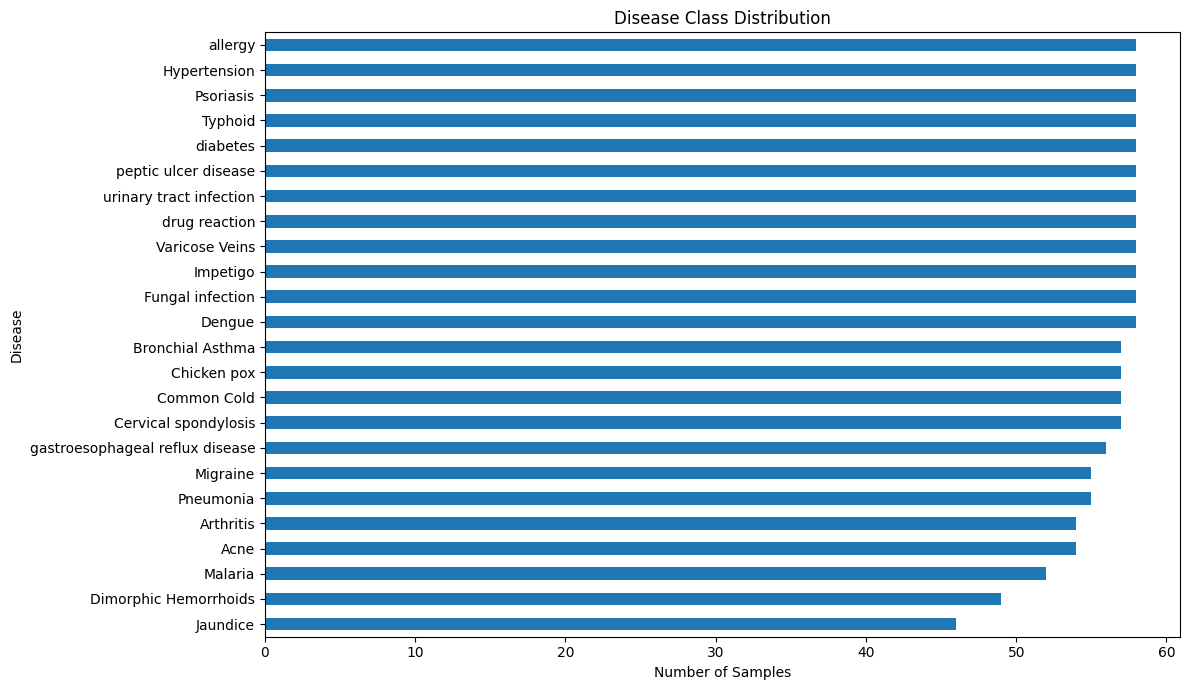

count    1345.000000
mean       27.499628
std         9.884762
min         4.000000
25%        23.000000
50%        29.000000
75%        34.000000
max        55.000000
Name: word_count, dtype: float64


<Figure size 640x480 with 0 Axes>

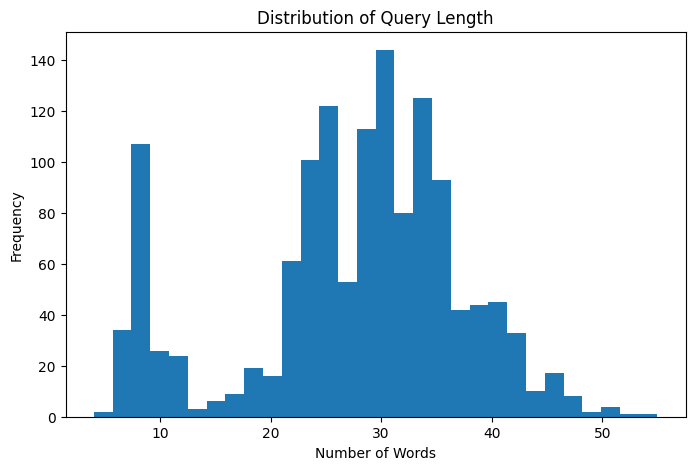

In [19]:
df = pd.read_csv("Symptom2Disease_augmented.csv")
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:", df.duplicated().sum())

df = df[["text", "label"]]
print(df.columns.tolist())

df = df[["text", "label"]].copy()
df = df.rename(columns={
    "disease": "label"
})

df = df.dropna(subset=["text", "label"])

df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(str)

df = df.drop_duplicates(subset=["text", "label"])

df = df.reset_index(drop=True)

print("Final shape:", df.shape)

print("Number of disease classes:", df["label"].nunique())

print("\nDisease classes:")
for disease in sorted(df["label"].unique()):
    print("-", disease)

class_counts = df["label"].value_counts()

print(class_counts)

plt.figure(figsize=(12, 7))

class_counts.sort_values().plot(kind="barh")

plt.title("Disease Class Distribution")
plt.xlabel("Number of Samples")
plt.ylabel("Disease")

plt.tight_layout()
plt.show()

plt.savefig(
    "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

df["word_count"] = df["text"].apply(
    lambda x: len(x.split())
)

df["character_count"] = df["text"].apply(len)

print(df["word_count"].describe())

plt.figure(figsize=(8, 5))

plt.hist(
    df["word_count"],
    bins=30
)

plt.title("Distribution of Query Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [20]:
def clean_text(text):
    text = str(text).lower()

    # Remove HTML if any
    text = re.sub(r"<.*?>", " ", text)

    # Replace unusual characters with spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["clean_text"] = df["text"].apply(clean_text)
for i in range(5):
    print("Original:", df["text"].iloc[i])
    print("Cleaned :", df["clean_text"].iloc[i])
    print()

label_encoder = LabelEncoder()

df["label_encoded"] = label_encoder.fit_transform(
    df["label"]
)

class_names = list(label_encoder.classes_)

print("Classes:", class_names)
print("Number of classes:", len(class_names))

X = df["clean_text"]
y = df["label_encoded"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF shape:", X_train_tfidf.shape)

baseline_model = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

baseline_model.fit(
    X_train_tfidf,
    y_train
)

baseline_pred = baseline_model.predict(X_test_tfidf)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

baseline_precision, baseline_recall, baseline_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        baseline_pred,
        average="weighted",
        zero_division=0
    )
)

print("Baseline Results")
print("----------------")
print("Accuracy :", baseline_accuracy)
print("Precision:", baseline_precision)
print("Recall   :", baseline_recall)
print("F1-score :", baseline_f1)

MAX_VOCAB_SIZE = 10000
MAX_SEQUENCE_LENGTH = 60
EMBEDDING_DIM = 128
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_SEQUENCE_LENGTH,
    standardize=None
)

vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        X_train.values
    ).batch(32)
)

vocab = vectorizer.get_vocabulary()

print("Vocabulary size:", len(vocab))
print("First 30 words:")
print(vocab[:30])

BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_train.values,
        y_train.values
    )
)

train_ds = (
    train_ds
    .shuffle(
        buffer_size=len(X_train),
        seed=SEED
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_val.values,
        y_val.values
    )
).batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        X_test.values,
        y_test.values
    )
).batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

num_classes = len(class_names)
vocab_size = len(vectorizer.get_vocabulary())

model = tf.keras.Sequential([

    vectorizer,

    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(
            96,
            return_sequences=False
        )
    ),

    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_health_chatbot.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Original: I have been feeling nauseous and have a constant urge to vomit, which is accompanied with mild fever and headache. 
Cleaned : i have been feeling nauseous and have a constant urge to vomit which is accompanied with mild fever and headache

Original: The chills and shivering I have been experiencing are accompanied by a feeling of coldness and high fever. I have also developed rashes on my arms and red spots on my neck.
Cleaned : the chills and shivering i have been experiencing are accompanied by a feeling of coldness and high fever i have also developed rashes on my arms and red spots on my neck

Original: I have redness, itching, and peeling of the skin.
Cleaned : i have redness itching and peeling of the skin

Original: I developed a minor rash near my nose a few days ago. Now, the rash is accompanied by a burning sensation and redness of the skin. I feel it is some kind of an infection.
Cleaned : i developed a minor rash near my nose a few days ago now the rash is accompa

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
27/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0817 - loss: 3.1745
Epoch 1: val_loss improved from None to 3.15490, saving model to best_health_chatbot.keras

Epoch 1: finished saving model to best_health_chatbot.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.0999 - loss: 3.1709 - val_accuracy: 0.2475 - val_loss: 3.1549
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2491 - loss: 3.1362
Epoch 2: val_loss improved from 3.15490 to 3.04579, saving model to best_health_chatbot.keras

Epoch 2: finished saving model to best_health_chatbot.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2370 - loss: 3.1206 - val_accuracy: 0.3069 - val_loss: 3.0458
Epoch 3/40
27/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2213 - loss: 2.8883
Epoch 3: val_loss improved from 3.04579 to 2.47166, saving model to best_health_chatbot.keras

Epoch 3: finished saving model to best_health_chatbot.keras
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy:

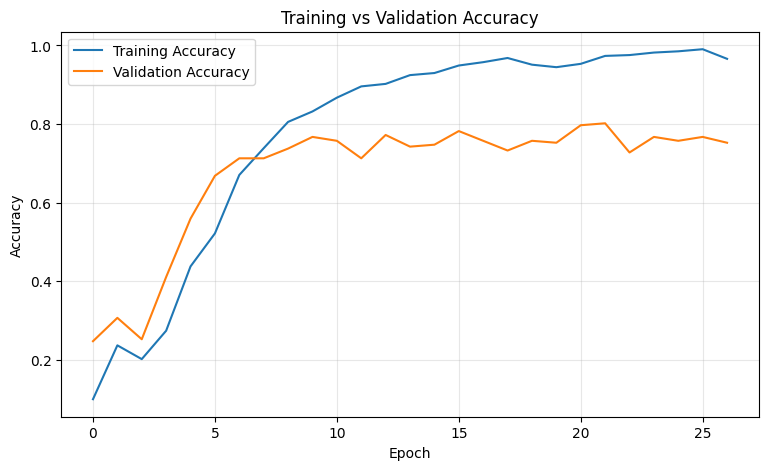

<Figure size 640x480 with 0 Axes>

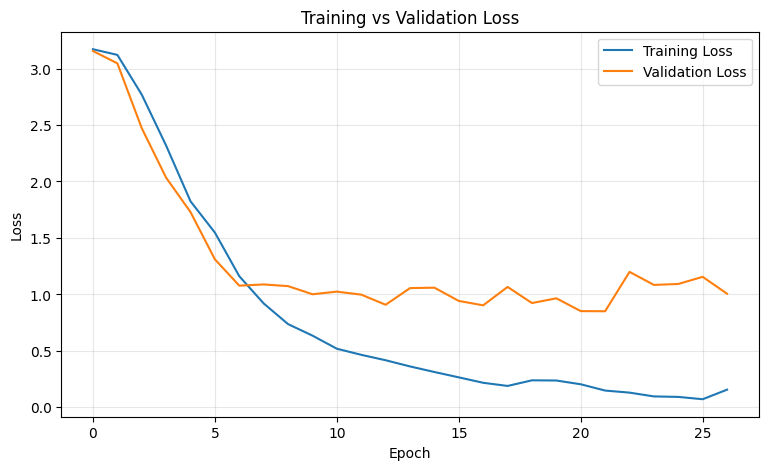

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7970 - loss: 0.9186 
Test Loss: 0.9186334609985352
Test Accuracy: 0.7970296740531921
1/7 ━━━━━━━━━━━━━━━━━━━━ 1s 242ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Deep Learning Results
---------------------
Accuracy : 0.7970296740531921
Precision: 0.812016558798737
Recall   : 0.7970297029702971
F1-score : 0.7970314377404467
                                 precision    recall  f1-score   support

                           Acne       1.00      1.00      1.00         8
                      Arthritis       0.86      0.75      0.80         8
               Bronchial Asthma       1.00      0.75      0.86         8
           Cervical spondylosis       0.67      0.75      0.71         8
                    Chicken pox       0.67      0.67      0.67         9
                    Common Cold       0.64      0.78      0.70         9
                         Dengue       0.67      0.67      0.67         9
          Dimorphic Hemorrhoids       0.83      0.71      0.77         7
               Fungal infection       0.88      0.78      0.82         9
                   Hypertension       0.82      1.00      0.90      

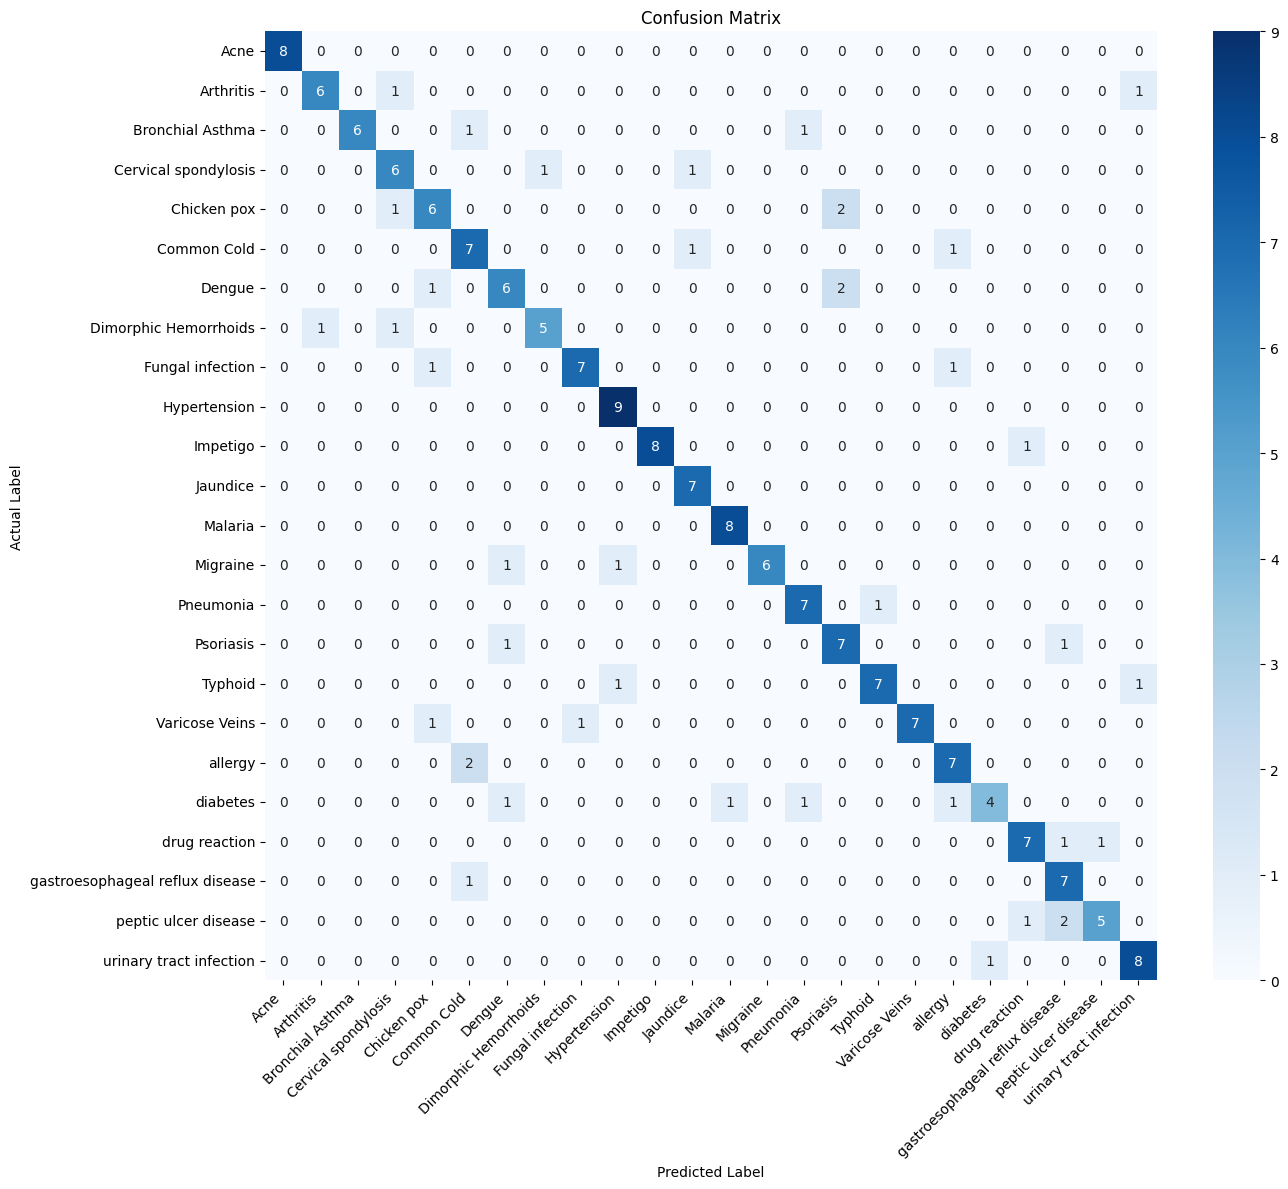

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,0.881188,0.889938,0.881188,0.881125
1,Bi-LSTM,0.797030,0.812017,0.797030,0.797031


<Figure size 640x480 with 0 Axes>

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

plt.savefig(
    "training_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

probabilities = model.predict(
    X_test.values,
    batch_size=32
)

y_pred = np.argmax(
    probabilities,
    axis=1
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

print("Deep Learning Results")
print("---------------------")
print("Accuracy :", test_accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    zero_division=0
)

print(report)

with open(
    "classification_report.txt",
    "w"
) as f:
    f.write(report)

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

results = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Bi-LSTM"
    ],
    "Accuracy": [
        baseline_accuracy,
        test_accuracy
    ],
    "Precision": [
        baseline_precision,
        precision
    ],
    "Recall": [
        baseline_recall,
        recall
    ],
    "F1 Score": [
        baseline_f1,
        f1
    ]
})

results

In [22]:
semantic_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_semantic = semantic_vectorizer.fit_transform(
    X_train
)

from sklearn.metrics.pairwise import cosine_similarity

def semantic_similarity_score(text):

    query_vector = semantic_vectorizer.transform(
        [clean_text(text)]
    )

    similarities = cosine_similarity(
        query_vector,
        X_train_semantic
    )

    return float(
        similarities.max()
    )
#THRESHOLDSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSs
CONFIDENCE_THRESHOLD = 0.65
SIMILARITY_THRESHOLD = 0.20
#TRESHOLDSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSSssss

def predict_health_topic(user_text):

    cleaned = clean_text(user_text)

    input_tensor = tf.constant(
        [cleaned],
        dtype=tf.string
    )

    prediction_tensor = model(
        input_tensor,
        training=False
    )

    probabilities = prediction_tensor.numpy()[0]

    predicted_index = int(
        np.argmax(probabilities)
    )

    predicted_label = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = float(
        probabilities[predicted_index]
    )

    similarity = semantic_similarity_score(
        cleaned
    )

    accepted = (
        (confidence >= CONFIDENCE_THRESHOLD and similarity >= SIMILARITY_THRESHOLD)
    )

    return {
        "label": predicted_label,
        "confidence": confidence,
        "similarity": similarity,
        "accepted": accepted,
        "probabilities": probabilities
    }

def show_top_predictions(user_text, top_k=5):

    cleaned = clean_text(user_text)

    input_tensor = tf.constant(
        [cleaned],
        dtype=tf.string
    )

    probabilities = model(
        input_tensor,
        training=False
    ).numpy()[0]

    top_indices = np.argsort(
        probabilities
    )[::-1][:top_k]

    print("User query:")
    print(user_text)
    print("\nTop predictions:")
    print("-" * 40)

    for rank, index in enumerate(top_indices, start=1):

        label = label_encoder.inverse_transform(
            [index]
        )[0]

        probability = probabilities[index]

        print(
            f"{rank}. {label:<35} "
            f"{probability:.4f} "
            f"({probability * 100:.2f}%)"
        )

result = predict_health_topic(
    "My nose is always blocked and I keep sneezing and my throat also hurts."
)

print("Predicted topic:", result["label"])
print("Confidence:", result["confidence"])
print("Similarity:", result["similarity"])
print("Accepted:", result["accepted"])

show_top_predictions(
    "My nose is always blocked and I keep sneezing and my throat also hurts"
)

Predicted topic: Common Cold
Confidence: 0.8350222110748291
Similarity: 0.3800453530465987
Accepted: True
User query:
My nose is always blocked and I keep sneezing and my throat also hurts

Top predictions:
----------------------------------------
1. Common Cold                         0.8350 (83.50%)
2. allergy                             0.0910 (9.10%)
3. Pneumonia                           0.0227 (2.27%)
4. gastroesophageal reflux disease     0.0205 (2.05%)
5. diabetes                            0.0167 (1.67%)


In [25]:
def generate_awareness_response(result):

    if not result["accepted"]:

        return (
            "I don't have enough confidence to provide a specific "
            "health-topic response from the information provided.\n\n"

            "You can describe a few more details, such as:\n"
            "• the main symptoms you are experiencing\n"
            "• how long they have been present\n"
            "• whether the symptoms are getting better or worse\n"
            "• any other symptoms occurring at the same time\n\n"

            "I can then provide general health-awareness information "
            "about potentially relevant topics.\n\n"

            "Important: This chatbot provides general health awareness "
            "information and is not a medical diagnostic tool."
        )

    label = result["label"]

    information = health_information.get(label)

    if information is None:
        return (
            "I could not find awareness information for the predicted topic."
        )

    response = []

    response.append(
        f"Possible health topic: {label}"
    )

    response.append(
        f"Model confidence: {result['confidence']:.1%}"
    )

    response.append("")

    response.append("ABOUT THIS TOPIC")
    response.append(
        information["overview"]
    )

    response.append("")

    response.append("COMMONLY ASSOCIATED FEATURES")

    for symptom in information["symptoms"]:
        response.append(f"• {symptom}")

    response.append("")

    response.append("HEALTH AWARENESS")

    for point in information["awareness"]:
        response.append(f"• {point}")

    response.append("")

    response.append("WHEN TO SEEK MEDICAL HELP")
    response.append(
        information["when_to_seek_help"]
    )

    response.append("")

    response.append(
        "Important: This information is for general health awareness "
        "and does not establish a diagnosis. Symptoms can have multiple "
        "causes, so persistent, severe or concerning symptoms should be "
        "evaluated by a qualified healthcare professional."
    )

    return "\n".join(response)

def health_chatbot(user_text):

    result = predict_health_topic(user_text)

    response = generate_awareness_response(result)

    return response

print(
    health_chatbot(
          "My nose is always blocked and I keep sneezing and my throat also hurts."
    )
)

import os
import joblib

os.makedirs("model", exist_ok=True)

# Save the complete Bi-LSTM model
model.save("model/health_model.keras")

# Save label encoder
joblib.dump(
    label_encoder,
    "model/label_encoder.pkl"
)

# Save TF-IDF semantic vectorizer
joblib.dump(
    semantic_vectorizer,
    "model/semantic_vectorizer.pkl"
)

# Save TF-IDF representation of training data
joblib.dump(
    X_train_semantic,
    "model/X_train_semantic.pkl"
)

print("All model files saved successfully!")

import tensorflow as tf

test_model = tf.keras.models.load_model(
    "model/health_model.keras"
)

test_prediction = test_model.predict(
    tf.constant([
        "My nose is always blocked and I keep sneezing and my throat also hurts"
    ]),
    verbose=0
)

print("Prediction shape:", test_prediction.shape)

test_model = tf.keras.models.load_model(
    "model/health_model.keras"
)

test_input = tf.constant(
    ["My nose is always blocked and I keep sneezing and my throat also hurts"],
    dtype=tf.string
)

prediction = test_model(
    test_input,
    training=False
)


Possible health topic: Common Cold
Model confidence: 83.5%

ABOUT THIS TOPIC
The common cold is a viral upper-respiratory infection that usually develops gradually and commonly affects the nose and throat. Most cases improve without specific treatment.

COMMONLY ASSOCIATED FEATURES
• Runny or blocked nose
• Sneezing
• Sore throat
• Cough
• Hoarse voice
• Tiredness
• Mild fever or body aches in some people

HEALTH AWARENESS
• Regular handwashing can reduce the spread of respiratory infections.
• Avoid sharing personal items with someone who is acutely ill.
• Rest and adequate fluid intake can support recovery.

WHEN TO SEEK MEDICAL HELP
Seek medical advice if symptoms are unusually severe, persist without improvement, or are accompanied by significant breathing difficulty, chest pain or other concerning symptoms.

Important: This information is for general health awareness and does not establish a diagnosis. Symptoms can have multiple causes, so persistent, severe or concerning symptoms

In [24]:
# ============================================================
# HEALTH AWARENESS KNOWLEDGE BASE
# ============================================================
# This information is intended for general health awareness.
# It is NOT a diagnostic system and should not replace
# evaluation by a qualified healthcare professional.

health_information = {

    # --------------------------------------------------------
    # 1. ACNE
    # --------------------------------------------------------
    "Acne": {
        "overview": (
            "Acne is a common skin condition that occurs when hair "
            "follicles become blocked with oil and dead skin cells. "
            "It commonly affects the face, chest and back and can "
            "range from a few spots to deeper, painful lesions."
        ),

        "symptoms": [
            "Blackheads or whiteheads",
            "Red or inflamed spots",
            "Pus-filled spots",
            "Deep or painful lumps in more severe cases",
            "Oily skin",
            "Changes in skin texture or acne scarring"
        ],

        "awareness": [
            "Avoid squeezing or picking spots because this can increase "
            "the risk of scarring.",
            "Use gentle skin cleansing rather than aggressive scrubbing.",
            "Non-comedogenic skincare products may help reduce pore blockage.",
            "Persistent, severe or scarring acne may require professional treatment."
        ],

        "when_to_seek_help": (
            "Seek professional medical advice if acne is severe, painful, "
            "causing scars, not improving with appropriate care, or having "
            "a significant effect on emotional wellbeing."
        )
    },


    # --------------------------------------------------------
    # 2. ARTHRITIS
    # --------------------------------------------------------
    "Arthritis": {
        "overview": (
            "Arthritis refers to conditions that affect joints and can "
            "cause pain, stiffness and swelling. Different forms of "
            "arthritis have different causes and treatment approaches."
        ),

        "symptoms": [
            "Joint pain",
            "Joint stiffness",
            "Joint swelling",
            "Reduced range of movement",
            "Joint tenderness",
            "Symptoms that may worsen during flare-ups"
        ],

        "awareness": [
            "Regular, appropriate physical activity can help maintain "
            "joint movement and overall physical function.",
            "Maintaining a healthy weight can reduce stress on weight-bearing joints.",
            "Treatment depends on the specific type of arthritis."
        ],

        "when_to_seek_help": (
            "Seek medical evaluation for persistent joint pain or swelling. "
            "Urgent assessment is appropriate when a joint suddenly becomes "
            "severely painful, swollen, hot or red, particularly when accompanied "
            "by fever or feeling very unwell."
        )
    },


    # --------------------------------------------------------
    # 3. BRONCHIAL ASTHMA
    # --------------------------------------------------------
    "Bronchial Asthma": {
        "overview": (
            "Asthma is a chronic condition in which inflammation and "
            "narrowing of the airways can make breathing difficult. "
            "Symptoms may vary over time and can become worse during "
            "an asthma attack."
        ),

        "symptoms": [
            "Wheezing",
            "Shortness of breath",
            "Persistent or recurring cough",
            "Chest tightness",
            "Symptoms that may become worse at night or during exercise"
        ],

        "awareness": [
            "Common triggers can include smoke, dust, air pollution, "
            "pollen, respiratory infections, strong fragrances and cold air.",
            "Identifying personal triggers can help reduce exposure.",
            "Asthma can usually be controlled with appropriate medical care."
        ],

        "when_to_seek_help": (
            "Severe difficulty breathing, rapidly worsening symptoms, "
            "difficulty speaking because of breathlessness, or symptoms "
            "that do not improve with a prescribed reliever require urgent "
            "medical attention."
        )
    },


    # --------------------------------------------------------
    # 4. CERVICAL SPONDYLOSIS
    # --------------------------------------------------------
    "Cervical spondylosis": {
        "overview": (
            "Cervical spondylosis is age-related wear and other degenerative "
            "changes affecting structures in the neck. Many people have these "
            "changes without symptoms."
        ),

        "symptoms": [
            "Neck pain",
            "Neck stiffness",
            "Pain that may extend toward the shoulder or arm",
            "Reduced neck movement",
            "Headaches associated with neck problems"
        ],

        "awareness": [
            "Regular movement and appropriate exercise can help maintain neck mobility.",
            "Avoid prolonged static positions and consider good workstation posture.",
            "Symptoms vary considerably between individuals."
        ],

        "when_to_seek_help": (
            "Seek medical assessment for persistent or worsening neck symptoms. "
            "New weakness, significant numbness, problems with walking or balance, "
            "or changes in bladder or bowel control require prompt medical evaluation."
        )
    },


    # --------------------------------------------------------
    # 5. CHICKEN POX
    # --------------------------------------------------------
    "Chicken pox": {
        "overview": (
            "Chickenpox is a contagious infection caused by the varicella-zoster "
            "virus. Its characteristic rash progresses from spots to itchy, "
            "fluid-filled blisters and then scabs."
        ),

        "symptoms": [
            "Itchy rash",
            "Fluid-filled blisters",
            "Fever",
            "Tiredness",
            "Loss of appetite",
            "Headache",
            "General feeling of being unwell"
        ],

        "awareness": [
            "Chickenpox spreads easily between people who are susceptible to infection.",
            "Avoid close contact with people at higher risk of severe illness while contagious.",
            "Vaccination is an important preventive measure where recommended."
        ],

        "when_to_seek_help": (
            "Medical advice is particularly important for babies, adults, "
            "pregnant people and people with weakened immune systems. "
            "Seek urgent help for severe breathing problems, confusion, "
            "severe illness or rapidly worsening symptoms."
        )
    },


    # --------------------------------------------------------
    # 6. COMMON COLD
    # --------------------------------------------------------
    "Common Cold": {
        "overview": (
            "The common cold is a viral upper-respiratory infection that "
            "usually develops gradually and commonly affects the nose and throat. "
            "Most cases improve without specific treatment."
        ),

        "symptoms": [
            "Runny or blocked nose",
            "Sneezing",
            "Sore throat",
            "Cough",
            "Hoarse voice",
            "Tiredness",
            "Mild fever or body aches in some people"
        ],

        "awareness": [
            "Regular handwashing can reduce the spread of respiratory infections.",
            "Avoid sharing personal items with someone who is acutely ill.",
            "Rest and adequate fluid intake can support recovery."
        ],

        "when_to_seek_help": (
            "Seek medical advice if symptoms are unusually severe, persist without "
            "improvement, or are accompanied by significant breathing difficulty, "
            "chest pain or other concerning symptoms."
        )
    },


    # --------------------------------------------------------
    # 7. DENGUE
    # --------------------------------------------------------
    "Dengue": {
        "overview": (
            "Dengue is a viral infection transmitted primarily by infected "
            "Aedes mosquitoes. Many infections are mild, but some can progress "
            "to severe dengue."
        ),

        "symptoms": [
            "High fever",
            "Severe headache",
            "Pain behind the eyes",
            "Muscle and joint pain",
            "Nausea or vomiting",
            "Rash",
            "Swollen glands in some cases"
        ],

        "awareness": [
            "Reduce mosquito exposure, particularly during the daytime when "
            "Aedes mosquitoes are active.",
            "Use appropriate mosquito repellents and protective clothing.",
            "Reduce mosquito breeding sites by removing standing water around homes."
        ],

        "when_to_seek_help": (
            "Warning signs of severe dengue can include severe abdominal pain, "
            "persistent vomiting, rapid breathing, bleeding from the gums or nose, "
            "blood in vomit or stool, extreme weakness, restlessness or unusual thirst. "
            "These require immediate medical attention."
        )
    },


    # --------------------------------------------------------
    # 8. DIMORPHIC HEMORRHOIDS
    # --------------------------------------------------------
    "Dimorphic Hemorrhoids": {
        "overview": (
            "The dataset label 'Dimorphic Hemorrhoids' is treated here as "
            "hemorrhoids (piles): swollen blood vessels in or around the anus. "
            "They may be internal or external."
        ),

        "symptoms": [
            "Bright-red bleeding during or after passing stool",
            "Itching around the anus",
            "Soreness or irritation",
            "Pain, especially with external hemorrhoids",
            "A lump or swelling around the anus"
        ],

        "awareness": [
            "A diet containing adequate fibre can help prevent constipation.",
            "Adequate fluid intake and regular physical activity can support healthy bowel habits.",
            "Avoid prolonged straining during bowel movements."
        ],

        "when_to_seek_help": (
            "Seek medical advice for persistent or recurrent rectal bleeding. "
            "Heavy bleeding, severe pain, dizziness or fainting requires urgent evaluation "
            "because rectal bleeding can have causes other than hemorrhoids."
        )
    },


    # --------------------------------------------------------
    # 9. FUNGAL INFECTION
    # --------------------------------------------------------
    "Fungal infection": {
        "overview": (
            "Fungal infections can affect the skin, scalp, feet, groin or nails. "
            "Ringworm is one common example and is caused by fungi rather than worms."
        ),

        "symptoms": [
            "Itchy skin",
            "Scaly or dry rash",
            "Red or darker patches",
            "Circular or ring-shaped rash in some infections",
            "Swelling or irritation",
            "Patchy hair loss when the scalp is affected"
        ],

        "awareness": [
            "Keep affected skin clean and dry.",
            "Avoid sharing towels, clothing or personal items when a contagious fungal infection is suspected.",
            "Use appropriate antifungal treatment as advised by a healthcare professional or pharmacist."
        ],

        "when_to_seek_help": (
            "Seek professional advice if the infection affects the scalp, "
            "is widespread, keeps returning, or does not improve with appropriate "
            "antifungal treatment."
        )
    },


    # --------------------------------------------------------
    # 10. HYPERTENSION
    # --------------------------------------------------------
    "Hypertension": {
        "overview": (
            "Hypertension, or high blood pressure, is persistent elevation of "
            "blood pressure in the arteries. It often causes no noticeable symptoms, "
            "so measuring blood pressure is important."
        ),

        "symptoms": [
            "Often no noticeable symptoms",
            "Headache can occur, particularly with very high blood pressure",
            "Blurred or altered vision",
            "Dizziness",
            "Chest discomfort",
            "Shortness of breath in severe cases"
        ],

        "awareness": [
            "Regular blood-pressure checks help identify hypertension.",
            "Reducing excessive dietary salt can help lower blood pressure.",
            "Regular physical activity and a balanced diet support cardiovascular health.",
            "Avoid tobacco and limit harmful alcohol consumption.",
            "Take prescribed blood-pressure medicines consistently."
        ],

        "when_to_seek_help": (
            "Very high blood pressure accompanied by severe headache, chest pain, "
            "difficulty breathing, confusion, weakness, vision changes or other "
            "serious symptoms requires immediate medical attention."
        )
    },


    # --------------------------------------------------------
    # 11. IMPETIGO
    # --------------------------------------------------------
    "Impetigo": {
        "overview": (
            "Impetigo is a contagious bacterial infection of the skin. "
            "It commonly begins as red sores or blisters that break and "
            "form characteristic golden-brown crusts."
        ),

        "symptoms": [
            "Red sores",
            "Small blisters",
            "Golden-brown or honey-coloured crusts",
            "Itching",
            "Soreness",
            "Spreading skin lesions"
        ],

        "awareness": [
            "Good hand hygiene helps reduce transmission.",
            "Avoid sharing towels, clothing or personal items.",
            "Avoid scratching affected areas.",
            "Follow professional advice regarding treatment and contagiousness."
        ],

        "when_to_seek_help": (
            "Seek medical advice when impetigo is suspected, particularly if "
            "lesions are spreading, recurrent or associated with significant illness."
        )
    },


    # --------------------------------------------------------
    # 12. JAUNDICE
    # --------------------------------------------------------
    "Jaundice": {
        "overview": (
            "Jaundice describes yellowing of the skin or, more noticeably, "
            "the whites of the eyes caused by increased bilirubin in the body. "
            "It is a sign rather than a single disease and can have many causes."
        ),

        "symptoms": [
            "Yellowing of the skin",
            "Yellowing of the whites of the eyes",
            "Dark urine",
            "Pale stools",
            "Itchy skin",
            "Other symptoms depending on the underlying cause"
        ],

        "awareness": [
            "Jaundice should not be treated as a diagnosis by itself.",
            "Possible causes include liver disease, hepatitis, gallstones and other conditions.",
            "The underlying cause needs appropriate medical evaluation."
        ],

        "when_to_seek_help": (
            "New yellowing of the skin or eyes should receive prompt medical assessment. "
            "Urgent care is especially important when jaundice is accompanied by severe "
            "abdominal pain, confusion, fever, vomiting or significant deterioration."
        )
    },


    # --------------------------------------------------------
    # 13. MALARIA
    # --------------------------------------------------------
    "Malaria": {
        "overview": (
            "Malaria is a potentially serious infectious disease caused by "
            "Plasmodium parasites and transmitted through infected mosquitoes. "
            "Early diagnosis and treatment are important."
        ),

        "symptoms": [
            "Fever",
            "Chills",
            "Headache",
            "Sweating",
            "Weakness or fatigue",
            "Muscle aches",
            "Other symptoms may develop as illness becomes more severe"
        ],

        "awareness": [
            "Use mosquito nets, repellents and appropriate protective clothing in areas where malaria occurs.",
            "Reduce mosquito exposure and follow local malaria-control recommendations.",
            "Travellers to malaria-risk regions should obtain location-specific preventive advice."
        ],

        "when_to_seek_help": (
            "Fever after possible exposure to malaria requires prompt medical assessment, "
            "especially in a malaria-risk area or after travel to one. Severe weakness, "
            "confusion, breathing difficulty, seizures or loss of consciousness require emergency care."
        )
    },


    # --------------------------------------------------------
    # 14. MIGRAINE
    # --------------------------------------------------------
    "Migraine": {
        "overview": (
            "Migraine is a neurological condition that can cause attacks of "
            "headache and other symptoms. Attacks vary between individuals "
            "and may occur with or without aura."
        ),

        "symptoms": [
            "Moderate to severe headache",
            "Throbbing or pulsating head pain",
            "Nausea or vomiting",
            "Sensitivity to light",
            "Sensitivity to sound",
            "Visual changes or other aura symptoms in some people",
            "Tiredness or changes in mood around an attack"
        ],

        "awareness": [
            "Keeping a record of possible triggers can help identify patterns.",
            "Regular sleep, meals and hydration may help some people manage attacks.",
            "Migraine treatment should be individualized with professional guidance when necessary."
        ],

        "when_to_seek_help": (
            "A sudden, extremely severe headache, a new neurological symptom, "
            "loss of consciousness, severe confusion, fever with neck stiffness, "
            "or a major change from a person's usual headache pattern requires urgent evaluation."
        )
    },


    # --------------------------------------------------------
    # 15. PNEUMONIA
    # --------------------------------------------------------
    "Pneumonia": {
        "overview": (
            "Pneumonia is an infection of the lungs that can be caused by "
            "different microorganisms, including bacteria and viruses. "
            "Severity ranges from mild to life-threatening."
        ),

        "symptoms": [
            "Cough",
            "Fever",
            "Shortness of breath",
            "Chest pain",
            "Fatigue",
            "Sweating or chills",
            "Nausea, vomiting or diarrhoea in some cases",
            "Confusion, particularly in older adults"
        ],

        "awareness": [
            "Vaccination can help prevent some infections that cause pneumonia.",
            "Good hand hygiene reduces transmission of respiratory infections.",
            "Avoiding tobacco smoke and reducing indoor air pollution can lower respiratory risk."
        ],

        "when_to_seek_help": (
            "Difficulty breathing, bluish lips or skin, severe chest pain, "
            "confusion, inability to stay awake, or rapidly worsening symptoms "
            "require urgent medical attention."
        )
    },


    # --------------------------------------------------------
    # 16. PSORIASIS
    # --------------------------------------------------------
    "Psoriasis": {
        "overview": (
            "Psoriasis is a long-term inflammatory skin condition that can cause "
            "dry, itchy, sore and scaly patches. It is not contagious."
        ),

        "symptoms": [
            "Dry or flaky skin",
            "Itchy or sore patches",
            "Raised scaly plaques",
            "Changes in nail texture such as pits or dents",
            "Recurring flare-ups",
            "Joint pain or stiffness in people who develop psoriatic arthritis"
        ],

        "awareness": [
            "Psoriasis is not an infection and cannot be spread through contact.",
            "Moisturising treatments can help manage dry skin.",
            "Treatment depends on the type and severity of psoriasis.",
            "Persistent joint pain, stiffness or swelling should be medically assessed."
        ],

        "when_to_seek_help": (
            "Seek medical advice for new or worsening psoriasis symptoms, "
            "especially when joints become painful, stiff or swollen. "
            "Rapidly widespread redness or pus-filled lesions require urgent evaluation."
        )
    },


    # --------------------------------------------------------
    # 17. TYPHOID
    # --------------------------------------------------------
    "Typhoid": {
        "overview": (
            "Typhoid fever is a bacterial infection caused by Salmonella Typhi. "
            "It is usually transmitted through contaminated food or water and "
            "can become serious without appropriate treatment."
        ),

        "symptoms": [
            "Prolonged fever",
            "Fatigue",
            "Headache",
            "Nausea",
            "Abdominal pain",
            "Constipation or diarrhoea",
            "Rash in some cases"
        ],

        "awareness": [
            "Use safe drinking water.",
            "Practice careful hand hygiene, especially after using the toilet and before handling food.",
            "Eat properly cooked food and use good food hygiene.",
            "Typhoid vaccination is an important preventive measure for people at appropriate risk."
        ],

        "when_to_seek_help": (
            "Persistent fever with gastrointestinal symptoms or possible exposure "
            "to contaminated food or water should receive medical evaluation. "
            "Severe abdominal symptoms, confusion, dehydration or significant deterioration "
            "require urgent care."
        )
    },


    # --------------------------------------------------------
    # 18. VARICOSE VEINS
    # --------------------------------------------------------
    "Varicose Veins": {
        "overview": (
            "Varicose veins are enlarged, twisted veins, most commonly in the legs. "
            "They are often not serious but can cause discomfort or skin changes."
        ),

        "symptoms": [
            "Visible enlarged or twisted veins",
            "Aching or pain in the legs",
            "Heavy or tired feeling in the legs",
            "Swelling around the ankles or legs",
            "Itching",
            "Skin colour or texture changes"
        ],

        "awareness": [
            "Regular movement can support healthy circulation.",
            "Avoid remaining seated or standing in one position for very long periods.",
            "Elevating the legs while resting may reduce discomfort for some people.",
            "Medical treatment may be appropriate when symptoms are significant."
        ],

        "when_to_seek_help": (
            "Seek medical advice for persistent pain, swelling or skin changes. "
            "Sudden significant swelling or pain in one leg, especially with breathing "
            "difficulty or chest pain, requires urgent medical assessment."
        )
    },


    # --------------------------------------------------------
    # 19. ALLERGY
    # --------------------------------------------------------
    "allergy": {
        "overview": (
            "An allergy occurs when the immune system reacts to a substance "
            "that is usually harmless to most people. Allergic reactions can "
            "range from mild symptoms to life-threatening anaphylaxis."
        ),

        "symptoms": [
            "Sneezing",
            "Runny or blocked nose",
            "Itchy or watery eyes",
            "Itchy skin or hives",
            "Skin rash",
            "Swelling",
            "Coughing or wheezing",
            "Digestive symptoms in some reactions"
        ],

        "awareness": [
            "Identifying and avoiding known triggers can reduce reactions.",
            "Common triggers include certain foods, medicines, insect stings and environmental allergens.",
            "People with known severe allergies should follow their clinician's emergency plan."
        ],

        "when_to_seek_help": (
            "Sudden swelling of the lips, tongue or throat, difficulty breathing, "
            "wheezing, fainting, severe dizziness or collapse can indicate anaphylaxis "
            "and requires emergency medical treatment."
        )
    },


    # --------------------------------------------------------
    # 20. DIABETES
    # --------------------------------------------------------
    "diabetes": {
        "overview": (
            "Diabetes is a chronic condition in which blood glucose levels "
            "are persistently elevated. Different types of diabetes have "
            "different causes and treatment requirements."
        ),

        "symptoms": [
            "Increased thirst",
            "Frequent urination",
            "Feeling tired",
            "Unintentional weight loss",
            "Blurred vision",
            "Increased hunger in some cases"
        ],

        "awareness": [
            "Type 2 diabetes can often be prevented or delayed through healthy lifestyle habits.",
            "Regular physical activity supports metabolic health.",
            "A balanced diet and maintaining a healthy body weight can reduce type 2 diabetes risk.",
            "People with diabetes need appropriate monitoring and professional management."
        ],

        "when_to_seek_help": (
            "Persistent excessive thirst, frequent urination, unexplained weight loss "
            "or other concerning symptoms should be medically evaluated. "
            "Confusion, severe weakness, vomiting, difficulty breathing or loss of "
            "consciousness in someone with diabetes requires urgent medical attention."
        )
    },


    # --------------------------------------------------------
    # 21. DRUG REACTION
    # --------------------------------------------------------
    "drug reaction": {
        "overview": (
            "A drug reaction can refer to an unwanted response to a medicine. "
            "Not every adverse drug reaction is an allergy; some are predictable "
            "side effects or interactions."
        ),

        "symptoms": [
            "Skin rash",
            "Itching",
            "Hives",
            "Swelling",
            "Nausea or vomiting",
            "Wheezing or breathing difficulty in severe allergic reactions",
            "Dizziness or collapse in severe reactions"
        ],

        "awareness": [
            "Keep a record of medicines that have caused previous reactions.",
            "Tell healthcare professionals about previous drug reactions.",
            "Do not restart a medicine that caused a serious reaction without professional advice.",
            "Medication changes should be discussed with a qualified healthcare professional."
        ],

        "when_to_seek_help": (
            "Swelling of the face, lips, tongue or throat, breathing difficulty, "
            "wheezing, fainting or collapse can indicate a severe allergic reaction "
            "and requires emergency medical attention."
        )
    },


    # --------------------------------------------------------
    # 22. GASTROESOPHAGEAL REFLUX DISEASE
    # --------------------------------------------------------
    "gastroesophageal reflux disease": {
        "overview": (
            "Gastroesophageal reflux disease (GERD/GORD) occurs when stomach "
            "contents repeatedly flow back into the oesophagus, causing symptoms "
            "such as heartburn or acid reflux."
        ),

        "symptoms": [
            "Heartburn",
            "Acid or sour taste in the mouth",
            "Regurgitation of stomach contents",
            "Belching",
            "Nausea",
            "Difficulty swallowing in some cases",
            "Symptoms that may worsen after meals or when lying down"
        ],

        "awareness": [
            "Avoiding personal trigger foods may reduce symptoms.",
            "Eating smaller meals may help some people.",
            "Avoid lying down soon after eating.",
            "Weight management may help people who are overweight.",
            "Persistent symptoms should be evaluated rather than repeatedly self-treated."
        ],

        "when_to_seek_help": (
            "Seek medical advice for persistent or worsening reflux, difficulty "
            "swallowing, unexplained weight loss or recurrent vomiting. "
            "Chest pain that is severe, sudden or associated with shortness of breath "
            "requires urgent evaluation because it may not be reflux."
        )
    },


    # --------------------------------------------------------
    # 23. PEPTIC ULCER DISEASE
    # --------------------------------------------------------
    "peptic ulcer disease": {
        "overview": (
            "Peptic ulcers are sores that develop in the lining of the stomach "
            "or upper part of the small intestine. Common causes include "
            "Helicobacter pylori infection and regular use of certain anti-inflammatory medicines."
        ),

        "symptoms": [
            "Upper abdominal pain",
            "Burning abdominal discomfort",
            "Indigestion",
            "Heartburn",
            "Bloating",
            "Nausea or vomiting",
            "Feeling unusually full after eating"
        ],

        "awareness": [
            "Persistent or recurrent upper abdominal pain should be evaluated.",
            "Regular use of NSAID pain medicines can contribute to ulcers in some people.",
            "H. pylori infection may require specific testing and treatment."
        ],

        "when_to_seek_help": (
            "Vomiting blood, vomit that resembles coffee grounds, black or bloody stools, "
            "severe abdominal pain, fainting or marked weakness requires emergency medical care."
        )
    },


    # --------------------------------------------------------
    # 24. URINARY TRACT INFECTION
    # --------------------------------------------------------
    "urinary tract infection": {
        "overview": (
            "A urinary tract infection (UTI) is an infection affecting part of "
            "the urinary system, such as the bladder or urethra. Some infections "
            "can spread to the kidneys and require prompt treatment."
        ),

        "symptoms": [
            "Burning or pain while urinating",
            "Needing to urinate more often",
            "Sudden urinary urgency",
            "Cloudy urine",
            "Blood in the urine",
            "Lower abdominal discomfort",
            "Back or side pain when the kidneys are involved",
            "Fever or chills in more significant infections"
        ],

        "awareness": [
            "Seek professional advice when symptoms suggest a UTI.",
            "Good personal hygiene can reduce infection risk.",
            "Adequate fluid intake is generally important for urinary health.",
            "Treatment depends on the location and severity of the infection."
        ],

        "when_to_seek_help": (
            "Fever, chills, pain in the back or side beneath the ribs, vomiting, "
            "confusion or feeling severely unwell can indicate a more serious urinary "
            "infection and requires prompt medical attention."
        )
    }
}


print("Health-awareness knowledge base created successfully.")
print("Number of entries:", len(health_information))
print("Dataset classes:", len(class_names))

Health-awareness knowledge base created successfully.
Number of entries: 24
Dataset classes: 24


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn joblib

import os
import re
import random
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ============================================================
# COMPLETE DATA AUGMENTATION BLOCK
# AI PUBLIC HEALTH CHATBOT
# ============================================================
#
# Upload:
#     Symptom2Disease.csv  <-- ORIGINAL 1200-row dataset
#
# Creates:
#     Symptom2Disease_augmented.csv
#
# Original examples : 1200
# New examples      : 192
# Expected total    : 1392
# ============================================================

import pandas as pd
from google.colab import files

# ============================================================
# 1. UPLOAD ORIGINAL DATASET
# ============================================================

print("Please upload the ORIGINAL Symptom2Disease.csv file.")
uploaded = files.upload()

# Check uploaded filename
uploaded_filename = list(uploaded.keys())[0]

print("\nUploaded file:", uploaded_filename)

# Read dataset
df = pd.read_csv(uploaded_filename)

print("\nOriginal dataset shape:", df.shape)
print("Original columns:", df.columns.tolist())

# Make sure required columns exist
if "label" not in df.columns or "text" not in df.columns:
    raise ValueError(
        "Dataset must contain 'label' and 'text' columns."
    )

print("\nFirst 5 rows:")
display(df.head())


# ============================================================
# 2. PARAPHRASED TRAINING EXAMPLES
# ============================================================

augmentation_data = {

    "Acne": [
        "I have pimples and blackheads on my face.",
        "My skin has many small pimples and whiteheads.",
        "I am getting frequent breakouts on my face.",
        "I have red bumps and pimples on my skin.",
        "My face has acne and clogged pores.",
        "I have several inflamed spots and pimples.",
        "I keep developing pimples around my face and forehead.",
        "My skin is breaking out with pimples and blackheads."
    ],

    "Arthritis": [
        "I have pain and stiffness in my joints.",
        "My joints are swollen and painful.",
        "I experience joint pain that makes movement difficult.",
        "My knees and other joints feel stiff and sore.",
        "I have aching joints, especially when I move.",
        "My joints hurt and feel stiff after resting.",
        "I experience swelling and discomfort around my joints.",
        "My joints feel painful, stiff, and difficult to move."
    ],

    "Bronchial Asthma": [
        "I have difficulty breathing and sometimes wheeze.",
        "I feel tightness in my chest and have trouble breathing.",
        "I experience wheezing and shortness of breath.",
        "My breathing becomes difficult and I hear a wheezing sound.",
        "I sometimes feel like I cannot get enough air.",
        "I have repeated episodes of breathlessness and chest tightness.",
        "I start wheezing when I have difficulty breathing.",
        "I experience shortness of breath along with chest tightness."
    ],

    "Cervical spondylosis": [
        "I have persistent neck pain and stiffness.",
        "My neck feels stiff and painful when I move it.",
        "I have neck pain that sometimes spreads toward my shoulders.",
        "I experience stiffness in my neck and discomfort around my shoulders.",
        "My neck hurts and I have difficulty moving it freely.",
        "I have pain and stiffness around my neck.",
        "I experience neck discomfort along with shoulder pain.",
        "My neck feels stiff, sore, and painful during movement."
    ],

    "Chicken pox": [
        "I have an itchy rash with small fluid-filled blisters.",
        "I have red spots and itchy blisters on my skin.",
        "I developed an itchy blister-like rash along with fever.",
        "My skin has many small itchy blisters.",
        "I have a spreading rash with fluid-filled spots.",
        "I developed red itchy spots that turned into blisters.",
        "I have fever followed by an itchy blistering rash.",
        "My body has itchy red spots and small blisters."
    ],

    "Common Cold": [
        "I have a runny nose and keep sneezing.",
        "I have a blocked nose, sore throat, and mild cough.",
        "I am sneezing frequently and have a runny nose.",
        "My throat is sore and I have nasal congestion.",
        "I have a cough, runny nose, and sneezing.",
        "I feel congested and have irritation in my throat.",
        "I have cold-like symptoms with sneezing and a stuffy nose.",
        "My nose is blocked and running, and I have a sore throat."
    ],

    "Dengue": [
        "I have a high fever with severe headache and body pain.",
        "I have fever, muscle pain, and pain behind my eyes.",
        "I feel extremely weak with fever and severe body aches.",
        "I have a high fever and intense muscle and joint pain.",
        "I have fever along with headache and pain behind my eyes.",
        "I feel very tired and have severe aches with a high fever.",
        "I have fever, weakness, headache, and strong muscle pain.",
        "I have a high fever with body aches and pain around my eyes."
    ],

    "Dimorphic Hemorrhoids": [
        "I have bleeding and discomfort during bowel movements.",
        "I notice blood when I pass stool and have anal discomfort.",
        "I have itching and pain around the anus.",
        "I experience bleeding during bowel movements.",
        "I have discomfort and itching around my rectal area.",
        "I notice bleeding along with pain when passing stool.",
        "I have swelling and irritation around the anus.",
        "I experience rectal discomfort, itching, and bleeding."
    ],

    "Fungal infection": [
        "I have an itchy red rash on my skin.",
        "My skin is irritated, itchy, and flaky.",
        "I have red patches with itching and scaling.",
        "I developed a persistent itchy skin rash.",
        "My skin has irritated patches that are becoming scaly.",
        "I have redness, itching, and peeling of the skin.",
        "There are itchy and flaky patches on my skin.",
        "I have a red, irritated rash that keeps itching."
    ],

    "Hypertension": [
        "I have been told that my blood pressure is high.",
        "My blood pressure readings are consistently elevated.",
        "I have high blood pressure and sometimes get headaches.",
        "My blood pressure has been higher than normal.",
        "I have been experiencing headaches along with high blood pressure.",
        "My blood pressure remains elevated when I check it.",
        "I was told that I have hypertension.",
        "I have high blood pressure and occasionally feel dizzy."
    ],

    "Impetigo": [
        "I have red sores on my skin that develop yellow crusts.",
        "I noticed small skin sores covered with a golden crust.",
        "My skin has red lesions with yellowish crusting.",
        "I have itchy sores that are forming crusts.",
        "I developed small red sores that started crusting.",
        "There are crusted sores around my skin.",
        "I have skin lesions with a yellow-brown crust.",
        "My skin has small sores that ooze and form crusts."
    ],

    "Jaundice": [
        "My skin has become yellowish and I feel very tired.",
        "My eyes look yellow and I feel weak.",
        "I noticed yellowing of my skin and eyes.",
        "My skin is turning yellow and I have been feeling fatigued.",
        "I have yellowish skin and dark-colored urine.",
        "My eyes have a yellow tint and I feel unusually tired.",
        "I have noticed a yellow discoloration of my skin.",
        "My skin and eyes look yellow and I feel exhausted."
    ],

    "Malaria": [
        "I have recurring fever with chills and sweating.",
        "I experience fever followed by chills and weakness.",
        "I have episodes of high fever and severe chills.",
        "I feel very weak and have repeated fever and chills.",
        "I have fever, sweating, headache, and body weakness.",
        "My fever comes with chills and intense tiredness.",
        "I experience recurring fever with headache and chills.",
        "I have episodes of fever followed by sweating and weakness."
    ],

    "Migraine": [
        "I have a severe headache with nausea.",
        "Bright light makes my headache worse.",
        "I experience intense headaches and sensitivity to light.",
        "My headache is accompanied by nausea.",
        "I get severe headaches and feel sick.",
        "I have a throbbing headache with nausea.",
        "I experience strong headaches and sensitivity to sound.",
        "I get intense headaches that become worse with bright light."
    ],

    "Pneumonia": [
        "I have a cough, fever, and difficulty breathing.",
        "I have chest pain along with a persistent cough.",
        "I am experiencing fever, cough, and shortness of breath.",
        "I have difficulty breathing and pain in my chest.",
        "My cough is accompanied by fever and weakness.",
        "I have a persistent cough with breathing difficulties.",
        "I feel short of breath and have a fever with coughing.",
        "I have chest discomfort, fever, and a severe cough."
    ],

    "Psoriasis": [
        "I have dry, thick, scaly patches on my skin.",
        "My skin has red patches covered with scales.",
        "I have itchy and flaky patches of skin.",
        "I developed thick, dry areas on my skin that keep peeling.",
        "My skin has raised red patches with silvery scales.",
        "I have persistent scaly patches that are itchy.",
        "There are dry, thick patches appearing on my skin.",
        "I have red irritated areas covered with flaky scales."
    ],

    "Typhoid": [
        "I have a persistent fever and feel very weak.",
        "I have prolonged fever with stomach discomfort.",
        "I feel tired and have a fever that does not go away.",
        "I have fever, weakness, and loss of appetite.",
        "I have a persistent high temperature with abdominal discomfort.",
        "I feel weak and have been experiencing fever for several days.",
        "I have fever along with stomach problems and tiredness.",
        "I have prolonged fever, weakness, and reduced appetite."
    ],

    "Varicose Veins": [
        "I have swollen and twisted veins in my legs.",
        "The veins in my legs look enlarged and prominent.",
        "I have visible bulging veins on my legs.",
        "My legs feel heavy and the veins look swollen.",
        "I have enlarged veins that are visible beneath my skin.",
        "My legs ache and I can see twisted veins.",
        "I have prominent veins in my legs with aching and heaviness.",
        "The veins in my legs appear swollen and twisted."
    ],

    "allergy": [
        "I have itching, sneezing, and a runny nose.",
        "I keep sneezing and my eyes are itchy.",
        "I developed an itchy rash after exposure to something.",
        "I have watery eyes and frequent sneezing.",
        "My nose is running and I keep feeling itchy.",
        "I experience sneezing, itching, and irritation.",
        "My eyes are watery and itchy and I keep sneezing.",
        "I developed itching and a rash after coming into contact with something."
    ],

    "diabetes": [
        "I am extremely thirsty and urinate frequently.",
        "I feel thirsty all the time and need to urinate often.",
        "I have increased hunger and frequent urination.",
        "I feel unusually thirsty and hungry.",
        "I have been drinking much more water than usual.",
        "I frequently need to use the bathroom and feel very thirsty.",
        "I have excessive thirst, increased hunger, and frequent urination.",
        "I am constantly thirsty and have been urinating more than usual."
    ],

    "drug reaction": [
        "I developed a rash after taking a medicine.",
        "My skin became itchy after I started a new medication.",
        "I have itching and a rash after taking a drug.",
        "I noticed skin irritation after using a new medicine.",
        "I developed red spots and itching after taking medication.",
        "My skin reacted after I took a new medicine.",
        "I have an unusual rash that appeared after taking medicine.",
        "I started experiencing itching and skin changes after medication."
    ],

    "gastroesophageal reflux disease": [
        "I frequently experience heartburn.",
        "I feel acid coming back into my throat.",
        "I get a burning sensation after eating.",
        "I have acid reflux after meals.",
        "I experience burning in my chest after eating.",
        "I often feel a sour taste coming back into my mouth.",
        "I have a burning feeling in my chest and throat after meals.",
        "I frequently experience acid reflux and heartburn."
    ],

    "peptic ulcer disease": [
        "I have a burning pain in my stomach.",
        "I experience stomach pain when my stomach is empty.",
        "I have recurring pain and burning in my upper abdomen.",
        "I feel a burning sensation in my stomach between meals.",
        "I have upper abdominal discomfort and pain.",
        "I experience stomach pain that sometimes improves after eating.",
        "I have a recurring burning sensation in my abdomen.",
        "I feel pain and discomfort in my upper stomach."
    ],

    "urinary tract infection": [
        "It burns when I urinate.",
        "I need to urinate very frequently.",
        "I feel pain while passing urine.",
        "I have a constant urge to urinate.",
        "I experience burning and discomfort when urinating.",
        "I feel like I need to urinate even when very little comes out.",
        "I have frequent urination along with a burning sensation.",
        "I experience pain and irritation when I pass urine."
    ]
}


# ============================================================
# 3. VERIFY ALL 24 LABELS
# ============================================================

original_labels = set(df["label"].unique())
augmentation_labels = set(augmentation_data.keys())

missing_labels = original_labels - augmentation_labels
extra_labels = augmentation_labels - original_labels

print("\nNumber of original classes:", len(original_labels))
print("Number of augmentation classes:", len(augmentation_labels))

if missing_labels:
    print("\nWARNING: Missing labels:")
    print(missing_labels)
    raise ValueError("Some original dataset labels do not have augmentation data.")

if extra_labels:
    print("\nWARNING: Extra labels:")
    print(extra_labels)
    raise ValueError("Some augmentation labels do not exist in the dataset.")

print("\n✓ All 24 dataset classes are covered.")


# ============================================================
# 4. CREATE AUGMENTED ROWS
# ============================================================

new_rows = []

for label, sentences in augmentation_data.items():

    for sentence in sentences:

        new_rows.append({
            "label": label,
            "text": sentence
        })

augmentation_df = pd.DataFrame(new_rows)

print("\nNew paraphrased examples:", len(augmentation_df))


# ============================================================
# 5. COMBINE ORIGINAL + NEW DATA
# ============================================================

original_training_data = df[["label", "text"]].copy()

augmented_df = pd.concat(
    [
        original_training_data,
        augmentation_df
    ],
    ignore_index=True
)


# ============================================================
# 6. REMOVE EXACT DUPLICATES
# ============================================================

before = len(augmented_df)

augmented_df = augmented_df.drop_duplicates(
    subset=["label", "text"]
).reset_index(drop=True)

after = len(augmented_df)

print("Duplicate rows removed:", before - after)


# ============================================================
# 7. SHUFFLE DATASET
# ============================================================

augmented_df = augmented_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)


# ============================================================
# 8. ADD INDEX COLUMN
# ============================================================

augmented_df.insert(
    0,
    "Unnamed: 0",
    range(len(augmented_df))
)


# ============================================================
# 9. SAVE AUGMENTED DATASET
# ============================================================

output_file = "Symptom2Disease_augmented.csv"

augmented_df.to_csv(
    output_file,
    index=False
)


# ============================================================
# 10. RESULTS
# ============================================================

print("\n" + "=" * 60)
print("DATA AUGMENTATION COMPLETE")
print("=" * 60)

print("\nOriginal examples :", len(df))
print("New examples      :", len(augmentation_df))
print("Final examples    :", len(augmented_df))

print("\nOutput file:")
print(output_file)

print("\nFinal shape:")
print(augmented_df.shape)

print("\nFinal columns:")
print(augmented_df.columns.tolist())


# ============================================================
# 11. CLASS DISTRIBUTION
# ============================================================

print("\nClass distribution:")

print(
    augmented_df["label"].value_counts()
)


# ============================================================
# 12. SHOW SAMPLE NEW EXAMPLES
# ============================================================

print("\nSample newly added examples:")

display(
    augmentation_df.head(15)
)


# ============================================================
# 13. DOWNLOAD AUGMENTED DATASET
# ============================================================

print("\nDownloading augmented dataset...")

files.download(output_file)